In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import multivariate_normal

ЧАСТЬ 1


In [ ]:
# Количество точек
M = 500

# Стандартные отклонения
sigma1 = 0.3
sigma2 = 0.8

# Угол поворота
alpha = np.deg2rad(30)

# Матрица исходной ковариации
C0 = np.diag([sigma1**2, sigma2**2])

# Матрица поворота
R = np.array([
    [np.cos(alpha), -np.sin(alpha)],
    [np.sin(alpha),  np.cos(alpha)]
])

print("C0 =")
print(C0)

print("\nR =")
print(R)

C0 =
[[0.09 0.  ]
 [0.   0.64]]

R =
[[ 0.8660254 -0.5      ]
 [ 0.5        0.8660254]]


In [ ]:
x1 = np.random.normal(
    loc=0,
    scale=sigma1,
    size=M
)

x2 = np.random.normal(
    loc=0,
    scale=sigma2,
    size=M
)
X_original = np.column_stack([x1, x2])

print(X_original.shape)

(500, 2)


In [ ]:
X = X_original @ R.T
C_sample = np.cov(X.T)
C_theoretical = R @ C0 @ R.T

print("Выборочная матрица:")
print(C_sample)

print("\nТеоретическая матрица:")
print(C_theoretical)

print("\nРазница:")
print(C_sample - C_theoretical)

Выборочная матрица:
[[ 0.23268674 -0.26145679]
 [-0.26145679  0.56399407]]

Теоретическая матрица:
[[ 0.2275     -0.23815699]
 [-0.23815699  0.5025    ]]

Разница:
[[ 0.00518674 -0.0232998 ]
 [-0.0232998   0.06149407]]


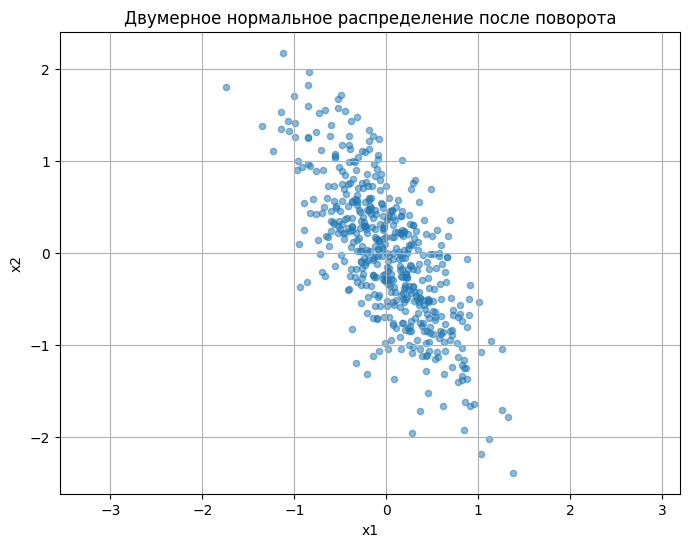

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    alpha=0.5,
    s=20
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Двумерное нормальное распределение после поворота")
plt.axis("equal")
plt.grid(True)

plt.show()

In [ ]:
x = np.linspace(-2, 2, 300)
y = np.linspace(-2, 2, 300)

X_grid, Y_grid = np.meshgrid(x, y)

grid = np.column_stack([
    X_grid.ravel(),
    Y_grid.ravel()
])

pdf = multivariate_normal(
    mean=[0, 0],
    cov=C_theoretical
).pdf(grid)

pdf = pdf.reshape(X_grid.shape)
C_inv = np.linalg.inv(C_theoretical)

mu = np.array([0.0, 0.0])

diff = grid - mu

mahalanobis_sq = np.sum(
    (diff @ C_inv) * diff,
    axis=1
)

mahalanobis_sq = mahalanobis_sq.reshape(X_grid.shape)

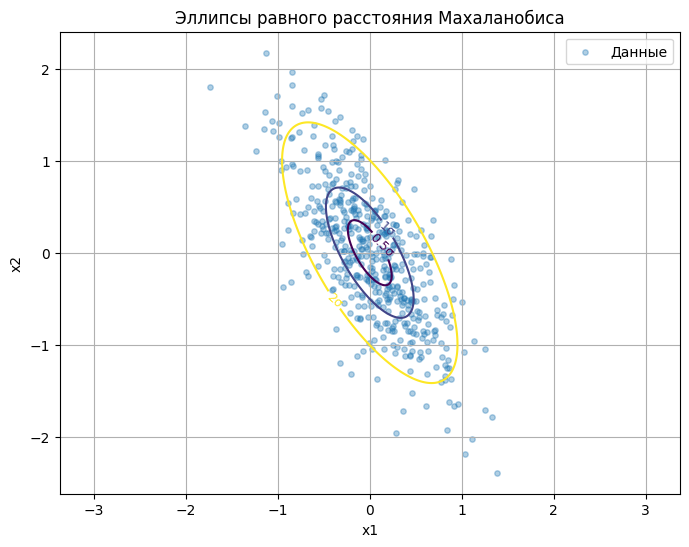

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    alpha=0.35,
    s=15,
    label="Данные"
)

contours = plt.contour(
    X_grid,
    Y_grid,
    mahalanobis_sq,
    levels=[0.5**2, 1**2, 2**2]
)

plt.clabel(
    contours,
    inline=True,
    fontsize=9,
    fmt={
        0.25: "0.5σ",
        1.0: "1σ",
        4.0: "2σ"
    }
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Эллипсы равного расстояния Махаланобиса")
plt.axis("equal")
plt.grid(True)
plt.legend()

plt.show()

In [ ]:
assert X.shape == (M, 2), \
    "Неверная размерность данных"

assert np.abs(np.cov(X.T)[0, 1]) > 0.1, \
    "Корреляция слишком мала (проверьте поворот)"

assert np.allclose(np.mean(X, axis=0), 0, atol=0.1), \
    "Среднее должно быть около 0"

print("Все проверки пройдены!")

Все проверки пройдены!


ЧАСТЬ - 2


In [ ]:
# Оценка среднего
mu_hat = np.mean(X, axis=0)

# Оценка ковариационной матрицы
C_hat = np.cov(X.T)

print("Оценка среднего:")
print(mu_hat)

print("\nОценка ковариационной матрицы:")
print(C_hat)

Оценка среднего:
[ 0.00840356 -0.02748704]

Оценка ковариационной матрицы:
[[ 0.23268674 -0.26145679]
 [-0.26145679  0.56399407]]


In [ ]:
x = np.linspace(-2, 2, 300)
y = np.linspace(-2, 2, 300)

X_grid, Y_grid = np.meshgrid(x, y)

grid_points = np.column_stack([
    X_grid.ravel(),
    Y_grid.ravel()
])
#создаем сетку

In [ ]:
m = multivariate_normal(
    mean=mu_hat,
    cov=C_hat
)

pdf_scipy = m.pdf(grid_points)

pdf_scipy = pdf_scipy.reshape(
    X_grid.shape
)

In [ ]:
det_C = np.linalg.det(C_hat)
inv_C = np.linalg.inv(C_hat)
diff = grid_points - mu_hat

quadratic_form = np.sum(
    (diff @ inv_C) * diff,
    axis=1
)
pdf_manual = (
    1 / (
        (2 * np.pi) ** (2 / 2)
        * np.sqrt(det_C)
    )
    * np.exp(-0.5 * quadratic_form)
)

pdf_manual = pdf_manual.reshape(
    X_grid.shape
)

In [ ]:
max_difference = np.max(
    np.abs(pdf_manual - pdf_scipy)
)

print("Максимальная разница:")
print(max_difference)

Максимальная разница:
1.942890293094024e-16


In [ ]:
assert np.allclose(
    pdf_manual,
    pdf_scipy,
    atol=1e-8
), "Ручное вычисление отличается от scipy"

print("PDF совпадают!")

PDF совпадают!


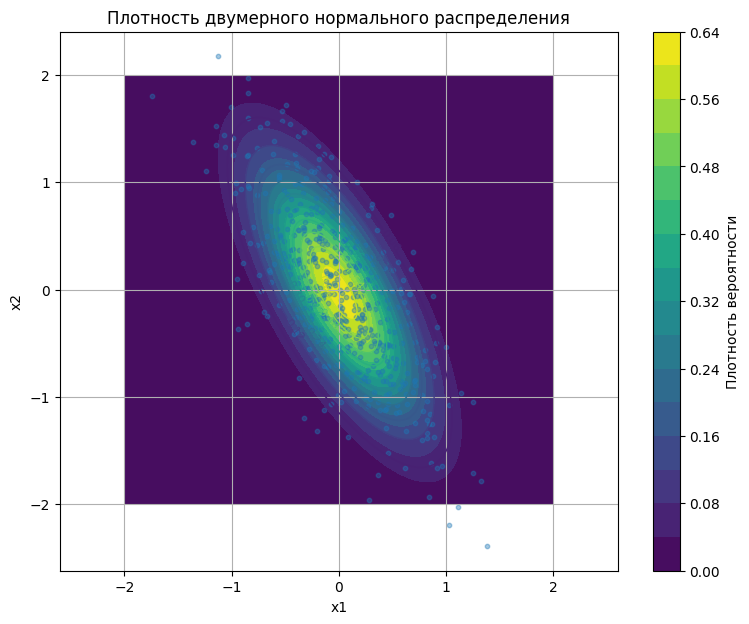

In [ ]:
plt.figure(figsize=(9, 7))

# Заливка плотности
filled = plt.contourf(
    X_grid,
    Y_grid,
    pdf_manual,
    levels=20
)

# Линии уровня
contours = plt.contour(
    X_grid,
    Y_grid,
    pdf_manual,
    levels=10,
    linewidths=1
)

# Подписи линий
plt.clabel(
    contours,
    inline=True,
    fontsize=8
)

# Исходные точки
plt.scatter(
    X[:, 0],
    X[:, 1],
    s=10,
    alpha=0.4
)

plt.colorbar(
    filled,
    label="Плотность вероятности"
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Плотность двумерного нормального распределения")
plt.axis("equal")
plt.grid(True)

plt.show()

ЧАСТЬ 3

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import multivariate_normal

# Количество объектов в каждом классе
n_samples = 300

# ==============================
# Класс 0
# ==============================

mu0 = np.array([-0.5, 0.5])

C0 = np.array([
    [0.2,  0.1],
    [0.1,  0.3]
])

# ==============================
# Класс 1
# ==============================

mu1 = np.array([0.5, -0.5])

C1 = np.array([
    [0.3, -0.1],
    [-0.1, 0.2]
])

In [ ]:
X0 = np.random.multivariate_normal(
    mean=mu0,
    cov=C0,
    size=n_samples
)

X1 = np.random.multivariate_normal(
    mean=mu1,
    cov=C1,
    size=n_samples
)
print(X0.shape)
print(X1.shape)

(300, 2)
(300, 2)


In [ ]:
X = np.vstack([X0, X1])

y = np.hstack([
    np.zeros(n_samples),
    np.ones(n_samples)
])

print("X shape:", X.shape)
print("y shape:", y.shape)
#объединяем

X shape: (600, 2)
y shape: (600,)


In [ ]:
prior0 = np.mean(y == 0)
prior1 = np.mean(y == 1)

print("P(y=0) =", prior0)
print("P(y=1) =", prior1)

#проверяем априорные вероятности

P(y=0) = 0.5
P(y=1) = 0.5


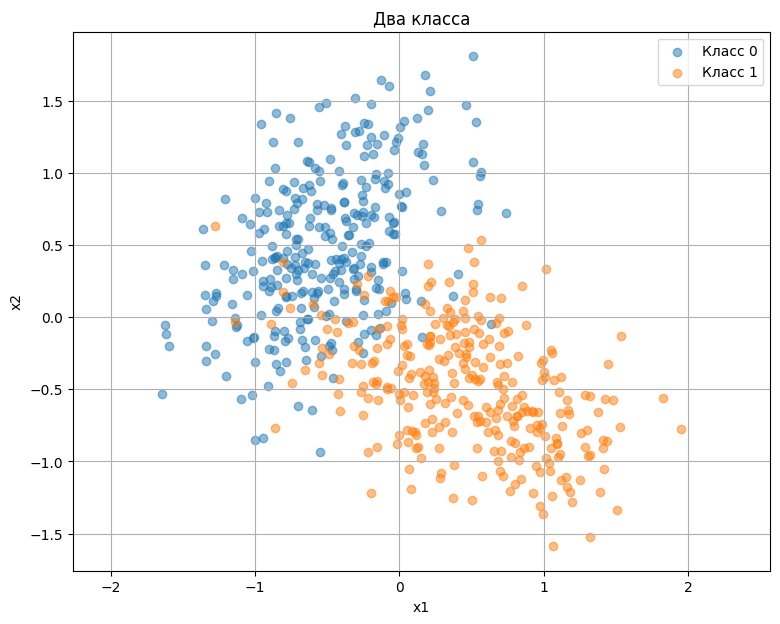

In [ ]:
plt.figure(figsize=(9, 7))

plt.scatter(
    X0[:, 0],
    X0[:, 1],
    alpha=0.5,
    label="Класс 0"
)

plt.scatter(
    X1[:, 0],
    X1[:, 1],
    alpha=0.5,
    label="Класс 1"
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Два класса")
plt.grid(True)
plt.axis("equal")
plt.legend()

plt.show()

In [ ]:
x_min, x_max = -2, 2 #Создаём сетку
y_min, y_max = -2, 2

xx = np.linspace(x_min, x_max, 400)
yy = np.linspace(y_min, y_max, 400)

XX, YY = np.meshgrid(xx, yy)

grid = np.column_stack([
    XX.ravel(),
    YY.ravel()
])
pdf0 = multivariate_normal( #Вычисляем плотность класса 0
    mean=mu0,
    cov=C0
).pdf(grid)

pdf1 = multivariate_normal( #Вычисляем плотность класса 0
    mean=mu1,
    cov=C1
).pdf(grid)

delta = ( #Вычисляем дельта(x)
    pdf0 * prior0
    -
    pdf1 * prior1
)
DELTA = delta.reshape(XX.shape)
print(DELTA.shape)

(400, 400)


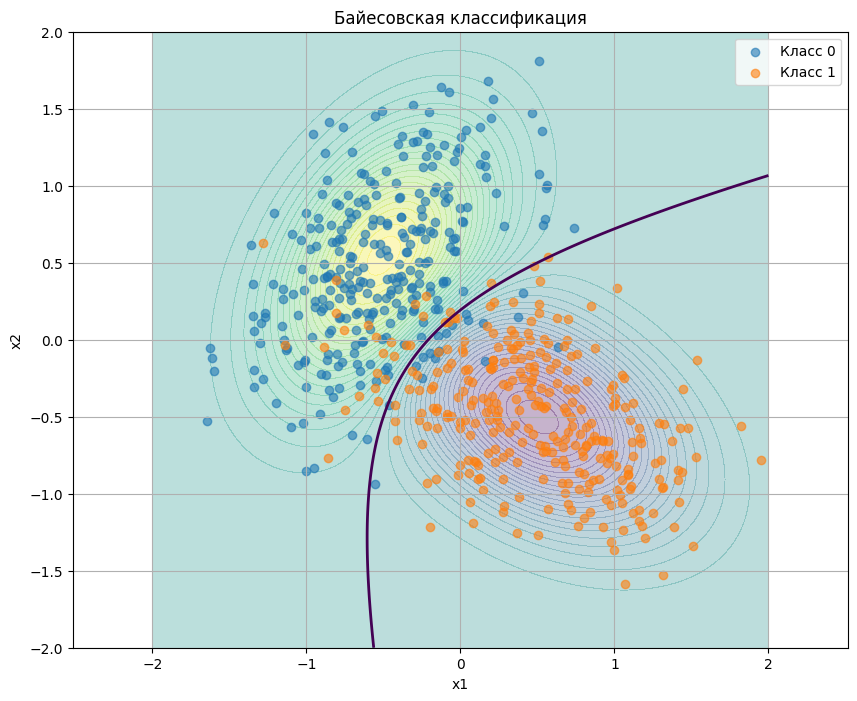

In [ ]:
plt.figure(figsize=(10, 8))

# Фон
plt.contourf(
    XX,
    YY,
    DELTA,
    levels=50,
    alpha=0.3
)

# Точки класса 0
plt.scatter(
    X0[:, 0],
    X0[:, 1],
    alpha=0.6,
    label="Класс 0"
)

# Точки класса 1
plt.scatter(
    X1[:, 0],
    X1[:, 1],
    alpha=0.6,
    label="Класс 1"
)

# Разделяющая поверхность
plt.contour(
    XX,
    YY,
    DELTA,
    levels=[0],
    linewidths=2
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Байесовская классификация")
plt.grid(True)
plt.axis("equal")
plt.legend()

plt.show()

ЧАСТЬ 4
